
# MODULE 6: DIMENSIONALITY REDUCTION USING PCA

**Student Name:** ANINDO PRITOM BARUA  
**Registration Number:** 23BDS0328  
**Dataset:** Indian Food Dataset  
**Phase:** 3

## Introduction

Dimensionality reduction is a technique used to reduce the number of input features in a dataset while preserving important information. Principal Component Analysis (PCA) transforms correlated variables into a smaller set of uncorrelated components.

## Objectives

1. Load and preprocess the Indian Food dataset.
2. Encode categorical variables and standardize numerical features.
3. Apply Principal Component Analysis (PCA).
4. Analyze explained variance and cumulative explained variance.
5. Estimate intrinsic dimensionality.
6. Visualize the dataset in two and three principal components.
7. Compare PCA with Singular Value Decomposition (SVD).

## Expected Outcome

Identify the number of principal components needed to retain at least 90% of the dataset's variance and examine patterns in the reduced feature space.


MODULE 6: DIMENSIONALITY REDUCTION USING PCA

Dataset Shape: (255, 10)

First Five Records:


,name,ingredients,diet,prep_time,cook_time,flavor_profile,course,state,region,total_time
0,Mihidana,"Besan flour, sugar, ghee",vegetarian,15,30,sweet,?,west bengal,east,45
1,Rabri,"Condensed milk, sugar, spices, nuts",vegetarian,10,45,sweet,unknown,uttar pradesh,north,55
2,Adhirasam,"Rice flour, jaggery, ghee, vegetable oil, elachi",vegetarian,10,50,sweet,dessert,west bengal,east,60
3,Anarsa,"Rice flour, jaggery, khus-khus seeds",vegetarian,10,50,sweet,dessert,maharashtra,west,60
4,Ariselu,"Rice flour, jaggery, ghee",vegetarian,15,75,sweet,dessert,andhra pradesh,south,90



Original Feature Count: 6
Encoded Feature Count: 24
Standardized Dataset Shape: (255, 24)

Components Required for 90% Variance: 16


,Component,Explained Variance,Cumulative Variance
0,1,0.1552,0.1552
1,2,0.0992,0.2543
2,3,0.0703,0.3247
3,4,0.0648,0.3895
4,5,0.0620,0.4515
5,6,0.0534,0.5049
6,7,0.0491,0.5540
7,8,0.0478,0.6019
8,9,0.0436,0.6455
9,10,0.0425,0.6880


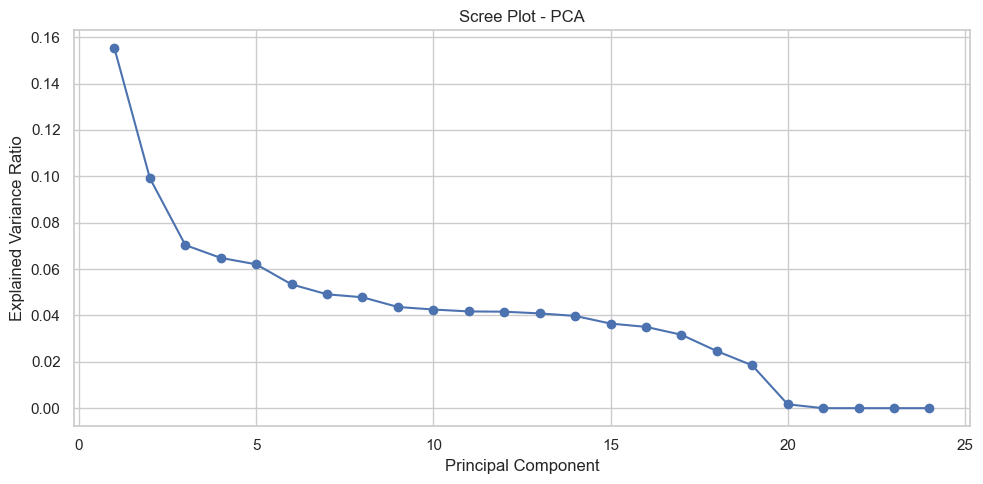

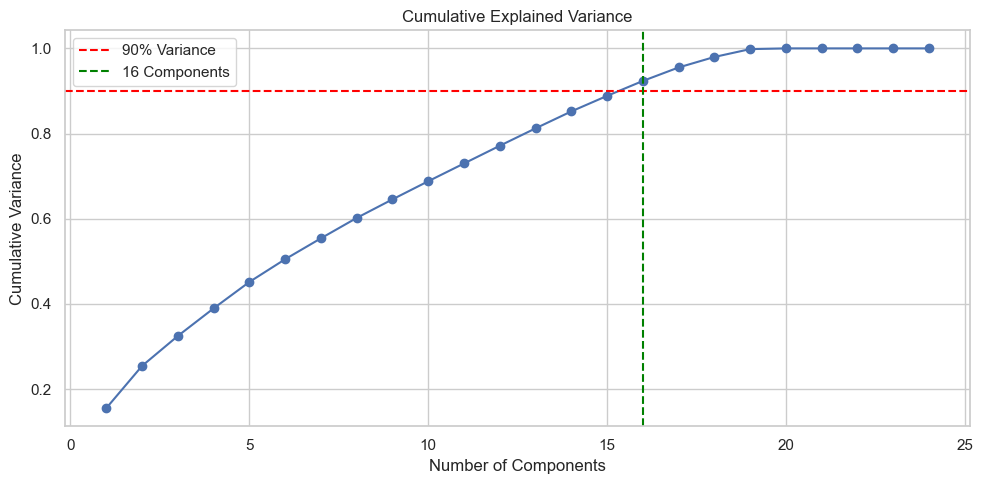

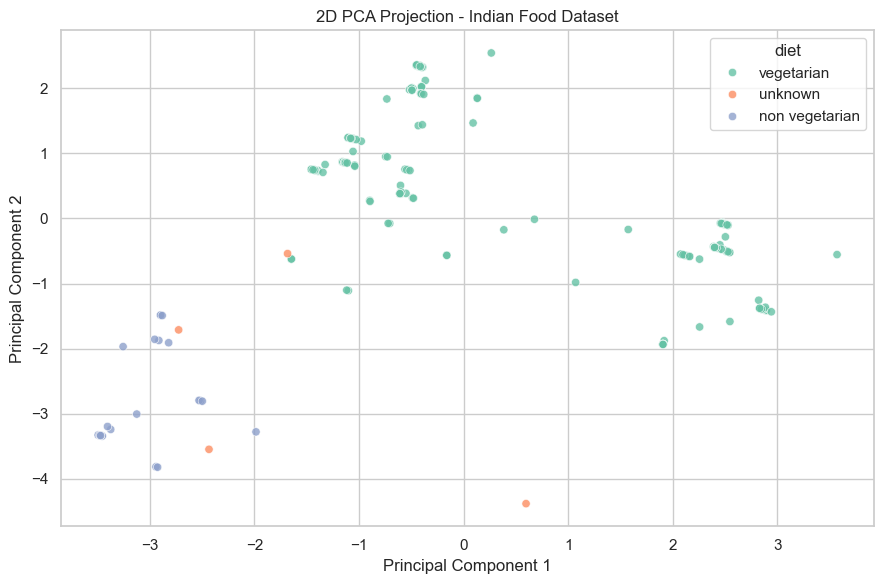


Variance Explained by 2 Components: 25.43 %


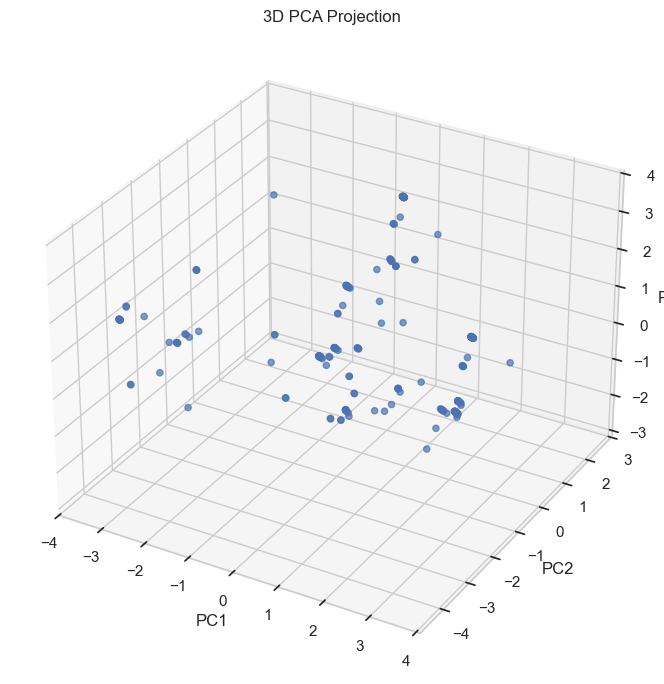

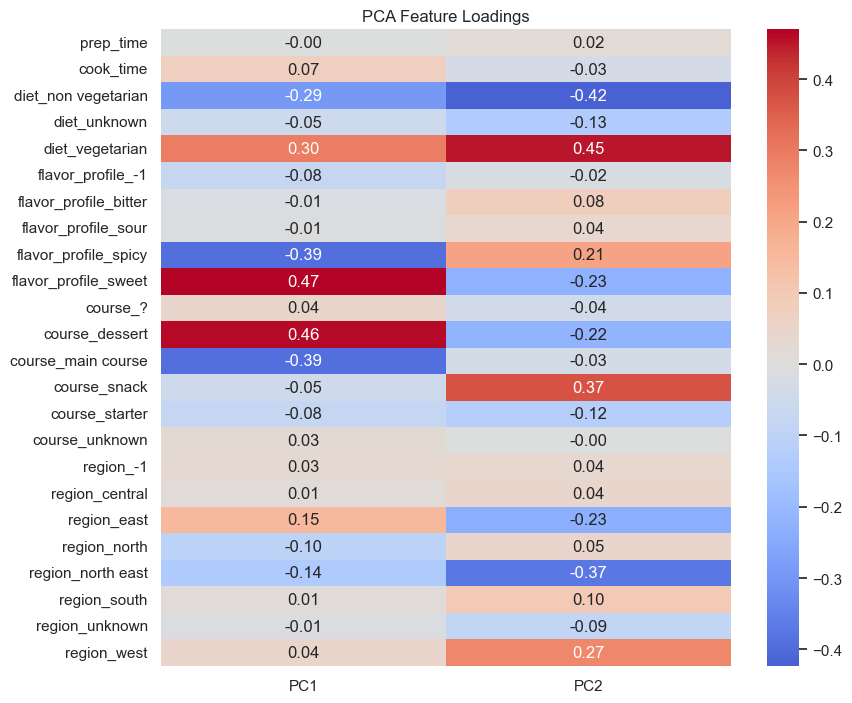

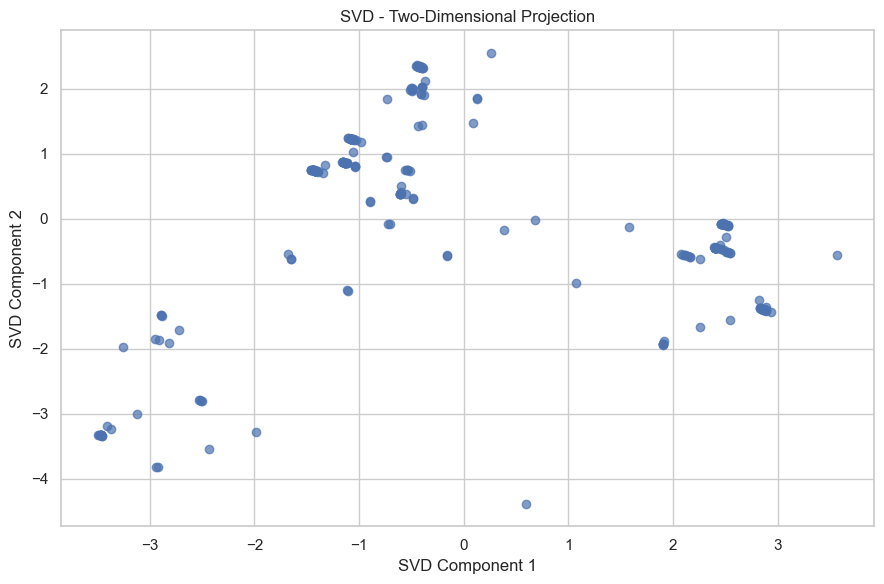


SVD Explained Variance: 25.43 %

Estimated Intrinsic Dimensionality: 14.41

DIMENSIONALITY REDUCTION COMPARISON


,Method,Components,Explained Variance (%)
0,PCA (2D),2,25.43
1,PCA (3D),3,32.47
2,SVD (2D),2,25.43



PCA Results Saved Successfully!
File: indian_food_pca_results.csv

MODULE 6 COMPLETED SUCCESSFULLY


In [2]:

# ==========================================================
# MODULE 6: DIMENSIONALITY REDUCTION USING PCA
# Student: ANINDO PRITOM BARUA
# Registration: 23BDS0328
# Dataset: Indian Food
# ==========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.impute import SimpleImputer
from mpl_toolkits.mplot3d import Axes3D

sns.set_theme(style="whitegrid")

# ----------------------------------------------------------
# 1. LOAD DATASET
# ----------------------------------------------------------

file_path = "../Phase 1/indian_food_cleaned.csv"

df = pd.read_csv(file_path)

print("=" * 60)
print("MODULE 6: DIMENSIONALITY REDUCTION USING PCA")
print("=" * 60)

print("\nDataset Shape:", df.shape)
print("\nFirst Five Records:")
display(df.head())

# ----------------------------------------------------------
# 2. FEATURE SELECTION AND PREPROCESSING
# ----------------------------------------------------------

# Avoid using total_time together with prep_time and
# cook_time because total_time is derived from them.

numeric_features = ["prep_time", "cook_time"]

categorical_features = [
    "diet",
    "flavor_profile",
    "course",
    "region"
]

numeric_features = [
    col for col in numeric_features if col in df.columns
]

categorical_features = [
    col for col in categorical_features if col in df.columns
]

X = df[numeric_features + categorical_features].copy()

for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")
    X.loc[X[col] < 0, col] = np.nan

for col in categorical_features:
    X[col] = (
        X[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
    )

if numeric_features:
    imputer = SimpleImputer(strategy="median")
    X[numeric_features] = imputer.fit_transform(
        X[numeric_features]
    )

X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    dtype=int
)

# Remove features with zero variance
X_encoded = X_encoded.loc[
    :, X_encoded.nunique() > 1
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

print("\nOriginal Feature Count:",
      len(numeric_features) + len(categorical_features))
print("Encoded Feature Count:", X_encoded.shape[1])
print("Standardized Dataset Shape:", X_scaled.shape)

# ----------------------------------------------------------
# 3. PRINCIPAL COMPONENT ANALYSIS
# ----------------------------------------------------------

pca = PCA()
pca.fit(X_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

n_components_90 = (
    np.searchsorted(cumulative_variance, 0.90) + 1
)

print("\nComponents Required for 90% Variance:",
      n_components_90)

variance_table = pd.DataFrame({
    "Component": np.arange(
        1, len(explained_variance) + 1
    ),
    "Explained Variance": explained_variance,
    "Cumulative Variance": cumulative_variance
})

display(variance_table.round(4))

# ----------------------------------------------------------
# 4. SCREE PLOT
# ----------------------------------------------------------

plt.figure(figsize=(10, 5))
plt.plot(
    variance_table["Component"],
    variance_table["Explained Variance"],
    marker="o"
)
plt.title("Scree Plot - PCA")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 5. CUMULATIVE EXPLAINED VARIANCE
# ----------------------------------------------------------

plt.figure(figsize=(10, 5))
plt.plot(
    variance_table["Component"],
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.90,
    color="red",
    linestyle="--",
    label="90% Variance"
)

plt.axvline(
    x=n_components_90,
    color="green",
    linestyle="--",
    label=f"{n_components_90} Components"
)

plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance")
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 6. TWO-DIMENSIONAL PCA
# ----------------------------------------------------------

pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca_2d[:, 0],
    y=X_pca_2d[:, 1],
    hue=df["diet"] if "diet" in df.columns else None,
    palette="Set2",
    alpha=0.8
)

plt.title("2D PCA Projection - Indian Food Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

print("\nVariance Explained by 2 Components:",
      round(
          pca_2d.explained_variance_ratio_.sum() * 100,
          2
      ), "%")

# ----------------------------------------------------------
# 7. THREE-DIMENSIONAL PCA
# ----------------------------------------------------------

pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X_pca_3d[:, 0],
    X_pca_3d[:, 1],
    X_pca_3d[:, 2],
    alpha=0.7
)

ax.set_title("3D PCA Projection")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")

plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 8. PCA FEATURE LOADINGS
# ----------------------------------------------------------

loadings = pd.DataFrame(
    pca_2d.components_.T,
    columns=["PC1", "PC2"],
    index=X_encoded.columns
)

plt.figure(figsize=(9, max(6, len(loadings) * 0.3)))

sns.heatmap(
    loadings,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 9. SINGULAR VALUE DECOMPOSITION
# ----------------------------------------------------------

svd = TruncatedSVD(
    n_components=2,
    random_state=42
)

X_svd = svd.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_svd[:, 0],
    X_svd[:, 1],
    alpha=0.7
)

plt.title("SVD - Two-Dimensional Projection")
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.tight_layout()
plt.show()

print("\nSVD Explained Variance:",
      round(
          svd.explained_variance_ratio_.sum() * 100,
          2
      ), "%")

# ----------------------------------------------------------
# 10. INTRINSIC DIMENSIONALITY
# ----------------------------------------------------------

eigenvalues = pca.explained_variance_
eigenvalues = eigenvalues[eigenvalues > 0]

effective_dimension = (
    eigenvalues.sum() ** 2
) / np.sum(eigenvalues ** 2)

print("\nEstimated Intrinsic Dimensionality:",
      round(effective_dimension, 2))

# ----------------------------------------------------------
# 11. COMPARISON SUMMARY
# ----------------------------------------------------------

comparison = pd.DataFrame({
    "Method": ["PCA (2D)", "PCA (3D)", "SVD (2D)"],
    "Components": [2, 3, 2],
    "Explained Variance (%)": [
        pca_2d.explained_variance_ratio_.sum() * 100,
        pca_3d.explained_variance_ratio_.sum() * 100,
        svd.explained_variance_ratio_.sum() * 100
    ]
})

print("\nDIMENSIONALITY REDUCTION COMPARISON")
display(comparison.round(2))

# ----------------------------------------------------------
# 12. SAVE PCA OUTPUT
# ----------------------------------------------------------

pca_output = df.copy()

pca_output["PC1"] = X_pca_2d[:, 0]
pca_output["PC2"] = X_pca_2d[:, 1]

pca_output.to_csv(
    "indian_food_pca_results.csv",
    index=False
)

print("\nPCA Results Saved Successfully!")
print("File: indian_food_pca_results.csv")
print("\nMODULE 6 COMPLETED SUCCESSFULLY")



## Conclusion

In this experiment, Principal Component Analysis (PCA) was applied to the Indian Food dataset to reduce dimensionality and analyze the underlying feature structure.

### Key Observations

1. Numerical features were standardized and categorical features were encoded before applying PCA.
2. The scree plot illustrated the variance contribution of individual principal components.
3. The cumulative explained variance plot identified the number of components needed to retain at least 90% of the dataset's variance.
4. Two-dimensional and three-dimensional PCA projections were generated to visualize the reduced feature space.
5. Singular Value Decomposition (SVD) was applied as an alternative dimensionality reduction method.
6. Intrinsic dimensionality was estimated using the eigenvalue participation ratio.
7. PCA results were exported to a CSV file for further analysis.

### Final Outcome

The experiment demonstrates how PCA can transform a dataset with multiple numerical and encoded categorical features into a lower-dimensional representation.

The number of components required, explained variance, and visual patterns should be interpreted using the generated results.
